# IADS5 · TP integrador — Ortelana Textil
### Actividad 07 · Validación cruzada y estabilidad

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 07 · Validación cruzada y estabilidad

**Qué se espera:** Aplicá StratifiedKFold de 10 particiones a los tres modelos de árbol sobre entrenamiento. Mostrá los diez scores, media y desvío estándar; compará la estabilidad entre modelos.

**Evidencia a entregar:** Tabla de media ± desviación estándar de CV.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score

cat_cols = ["Sucursal_ID", "Tela_ID"]          # identificadores: van con one-hot
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline(modelo):
    """One-hot para los identificadores y numéricas sin cambios (los árboles no necesitan escalado)."""
    preprocesador = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols),
    ], verbose_feature_names_out=False)   # nombres de columnas cortos, p. ej. "Tela_ID_TELA-001"
    return Pipeline([("prep", preprocesador), ("modelo", modelo)])

# Los tres modelos de árbol de las actividades 05 y 06
arbol = crear_pipeline(DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE))
rf = crear_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
xgb = crear_pipeline(XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                   random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss"))

codificador = LabelEncoder().fit(y_train)   # XGBoost necesita las clases como números
y_train_num = codificador.transform(y_train)

In [3]:
# 7.1 StratifiedKFold de 10 particiones, solo sobre train
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

# XGBoost usa las clases codificadas: como el orden se conserva (B<C<M<S -> 0<1<2<3), los 10 folds son los mismos
scores = {
    "Árbol gini (depth=4)": cross_val_score(arbol, X_train, y_train, cv=cv10, scoring="f1_macro", n_jobs=-1),
    "Random Forest (100)": cross_val_score(rf, X_train, y_train, cv=cv10, scoring="f1_macro", n_jobs=-1),
    "XGBoost": cross_val_score(xgb, X_train, y_train_num, cv=cv10, scoring="f1_macro", n_jobs=-1),
}
tabla_folds = pd.DataFrame(scores, index=[f"Fold {i}" for i in range(1, 11)])
tabla_folds.round(4)

,Árbol gini (depth=4),Random Forest (100),XGBoost
Fold 1,0.6172,0.9661,0.8402
Fold 2,0.6420,0.9391,0.8612
Fold 3,0.6556,0.9732,0.8971
Fold 4,0.5799,0.9704,0.8724
Fold 5,0.6380,0.9680,0.9062
Fold 6,0.6240,0.9688,0.8664
Fold 7,0.6639,0.9702,0.8292
Fold 8,0.6217,0.9771,0.8736
Fold 9,0.6367,0.9702,0.8795
Fold 10,0.5612,0.9509,0.8721


,F1 macro CV media,F1 macro CV desvío,mín,máx,F1 macro test
Árbol gini (depth=4),0.6240,0.0303,0.5612,0.6639,0.6460
Random Forest (100),0.9654,0.0109,0.9391,0.9771,0.9751
XGBoost,0.8698,0.0219,0.8292,0.9062,0.8877


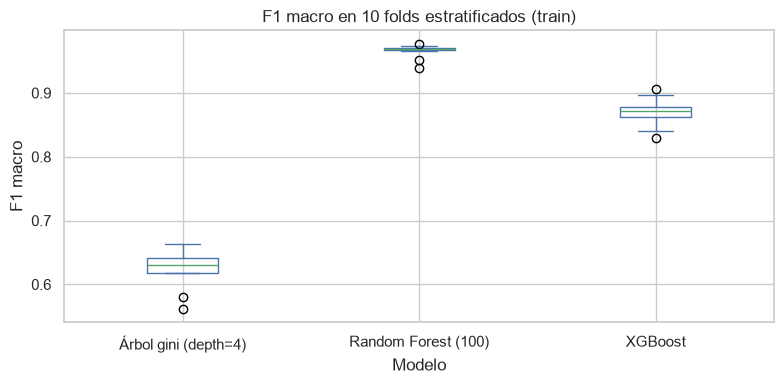

In [4]:
# 7.2 Media ± desvío estándar y comparación con test
arbol.fit(X_train, y_train)
rf.fit(X_train, y_train)
xgb.fit(X_train, y_train_num)
f1_test = [f1_score(y_test, arbol.predict(X_test), average="macro"),
           f1_score(y_test, rf.predict(X_test), average="macro"),
           f1_score(y_test, codificador.inverse_transform(xgb.predict(X_test)), average="macro")]

resumen = pd.DataFrame({
    "F1 macro CV media": tabla_folds.mean(),
    "F1 macro CV desvío": tabla_folds.std(ddof=0),   # desvío de los 10 folds
    "mín": tabla_folds.min(),
    "máx": tabla_folds.max(),
    "F1 macro test": f1_test,
})
display(resumen.round(4))

ax = tabla_folds.plot(kind="box", figsize=(8, 4))
ax.set(title="F1 macro en 10 folds estratificados (train)", ylabel="F1 macro", xlabel="Modelo")
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **CV:** `StratifiedKFold(n_splits=10, shuffle=True, random_state=42)` **solo sobre train**, con F1 macro.
- **Modelos:** el árbol gini (depth 4), RF y XGBoost. Elegimos el árbol gini como representante del árbol individual porque fue el mejor de la Actividad 05.
- **Estratificación:** mantiene en cada fold la proporción de las 4 clases.
- **Folds de XGBoost:** el target codificado conserva el orden de las clases (B<C<M<S → 0<1<2<3), así que los 10 folds son idénticos para los tres modelos.
- **Uso de `clone`:** el modelo se reajusta desde cero en cada fold.

**Interpretación de los resultados:**

| Modelo | F1 macro CV (media ± std) | rango | test |
|---|---|---|---|
| Árbol gini depth 4 | 0,624 ± 0,030 | 0,561–0,664 | 0,646 |
| Random Forest | **0,965 ± 0,011** | 0,939–0,977 | 0,975 |
| XGBoost | 0,870 ± 0,022 | 0,829–0,906 | 0,888 |

- **Desempeño y estabilidad:** RF es a la vez el mejor y el más estable: tiene el menor desvío y su peor fold (0,939) supera al mejor de XGBoost.
- **Árbol individual:** es el más inestable (std 0,030), con una diferencia de 10 puntos entre su peor y su mejor fold.
- **Test:** en los tres modelos el valor de test cae dentro del rango de CV, algo por encima de la media.

**Pregunta de análisis:** ¿Qué significa un desvío superior a 0,02? ¿Cambiaría tu elección si solo hubieras mirado test?
- **Desvío > 0,02:** el árbol (0,030) y XGBoost (0,022) lo superan. Significa que el F1 de un modelo puede cambiar ±2–3 puntos solo por qué filas le tocan.
  - Diferencias entre modelos menores a esa magnitud no son confiables.
  - Una sola partición puede dar una impresión optimista o pesimista. Por ejemplo, el árbol obtiene 0,646 en test, por encima de su media de CV de 0,624.
- **Si solo hubiera mirado test:** en este caso la elección no cambiaría, porque el orden RF > XGB > árbol es el mismo y las diferencias son muy grandes respecto del desvío. Pero con test solo no podríamos saber que RF además es el más estable, ni cuánto confiar en la diferencia. Elegir mirando test repetidamente convertiría al test en un conjunto de validación.

**Limitaciones o mejoras posibles:**
- Los folds no son independientes: comparten pares (Sucursal, Tela), así que el desvío subestima la variabilidad frente a datos realmente nuevos.
- Se podría usar `RepeatedStratifiedKFold` para tener una estimación más estable del desvío.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
